## Imports

In [21]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import importlib
from pricing.blackscholes import *


In [20]:
import pricing.blackscholes
importlib.reload(pricing.blackscholes)

<module 'pricing.blackscholes' from 'C:\\Users\\xprp2\\Documents\\python\\derivatives-research\\src\\pricing\\blackscholes.py'>

## Greeks spot price dependence

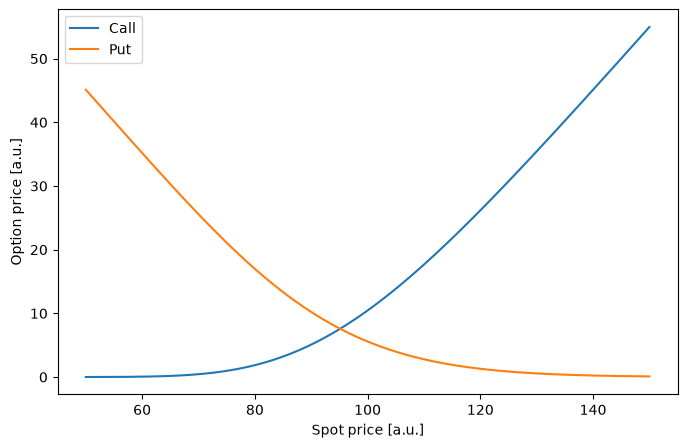

In [ ]:
S0_values = np.linspace(50, 150, 200)

# prices
K = 100
rate = 0.05
sigma = 0.20
T = 1.0

call_prices = [european_call_price(S0, K, rate, sigma, T) for S0 in S0_values]
put_prices = [european_put_price(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, call_prices, label="Call")
plt.plot(S0_values, put_prices, label="Put")
plt.xlabel("Spot price [a.u.]")
plt.ylabel("Option price [a.u.]")
plt.legend()
plt.show()

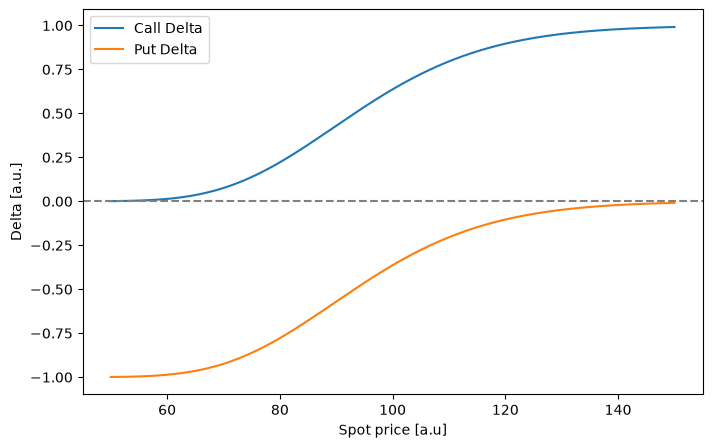

In [ ]:
# Delta
call_deltas = [call_delta(S0, K, rate, sigma, T) for S0 in S0_values]

put_deltas = [put_delta(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, call_deltas, label="Call delta")
plt.plot(S0_values, put_deltas, label="Put delta")
plt.xlabel("Spot price [a.u]")
plt.ylabel("Delta [a.u.]")
plt.axhline(y=0, linestyle="--", c='gray', )
plt.legend()
plt.show()

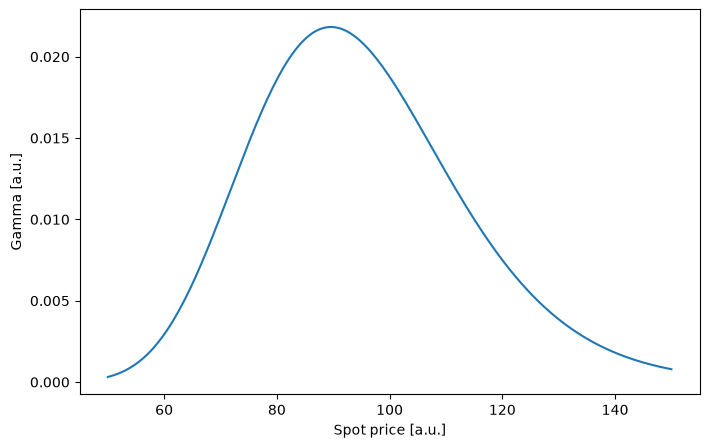

In [ ]:
# Gamma
gamma_values = [gamma(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, gamma_values)
plt.xlabel("Spot price [a.u.]")
plt.ylabel("Gamma [a.u.]")
plt.show()

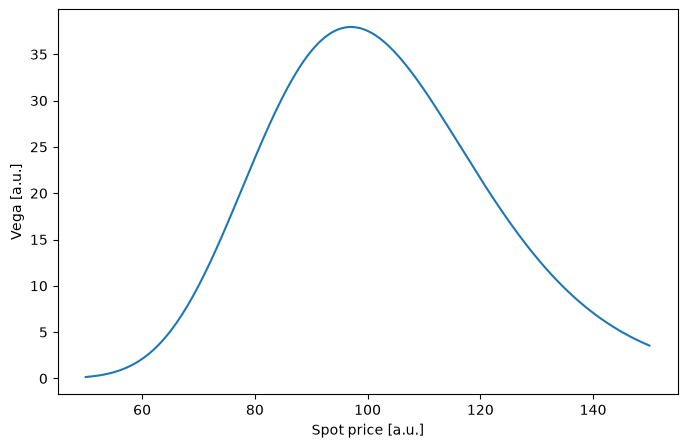

In [11]:
# Vega
vega_values = [vega(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, vega_values)
plt.xlabel("Spot price [a.u.]")
plt.ylabel("Vega [a.u.]")
plt.show()

## Implied volatility vs volatility smile

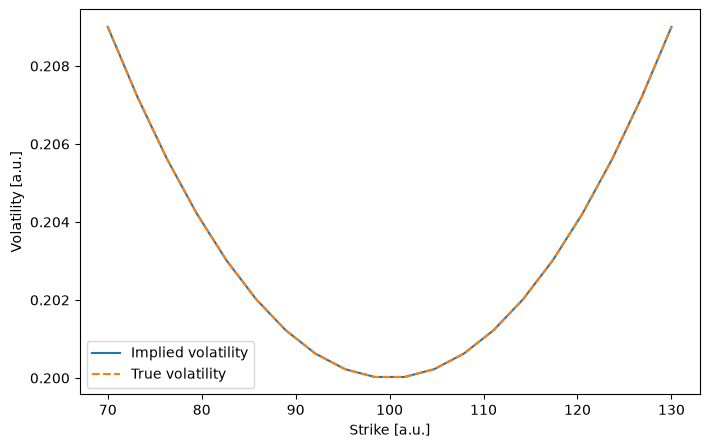

In [22]:
def volatility_smile(K):
    moneyness = K / 100
    return 0.20 + 0.10 * (moneyness - 1.0) ** 2

strike_prices = np.linspace(70, 130, 20)
true_sigma = 0.20

market_vols = [volatility_smile(K) for K in strike_prices]
market_prices = [european_call_price(S0=100, K=K, rate=0.05, sigma=sigma, T=1.0) for K, sigma in zip(strike_prices, market_vols)]
recovered_vols = [implied_volatility(market_price=price, S0=100, K=K,rate=0.05,T=1.0) for K, price in zip(strike_prices, market_prices)]

plt.figure(figsize=(8, 5))
plt.plot(strike_prices, recovered_vols, label="Implied volatility")
plt.plot(strike_prices, market_vols, linestyle="--", label="True volatility")

plt.xlabel("Strike [a.u.]")
plt.ylabel("Volatility [a.u.]")
plt.legend()
plt.show()